# 🚗 Machine Learning & Time Series Project: Used Car Price Analysis
**Course:** Machine Learning & Data Science Lab  
**Project:** Used Car Price Prediction, Classification & Trend Forecasting  
**Author:** Student Project  

---

### Project Overview:
In this project, we analyze the CarDekho used car dataset using three standard data science approaches:
1. **Linear Regression:** To predict the continuous resale price (`Selling_Price`) of a used car based on vehicle specifications.
2. **Logistic Regression:** To classify cars into **Budget** (`0`) vs **High-Price** (`1`) categories based on median pricing.
3. **Time Series Analysis & Forecasting:** To analyze how car prices have trended over the years (2003–2018), calculate moving averages, and forecast future average prices for upcoming years.


## Step 1: Importing Required Libraries


In [1]:
# Data manipulation and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn for Linear & Logistic Regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Statsmodels for Time Series Analysis & Forecasting
from statsmodels.tsa.api import Holt

print("All libraries imported successfully!")


All libraries imported successfully!


## Step 2: Loading and Inspecting the Dataset


In [2]:
# Loading the dataset from the data folder
df = pd.read_csv('data/raw/car data.csv')

# Checking shape and the first few records
print("Dataset Shape (Rows, Columns):", df.shape)
df.head()


Dataset Shape (Rows, Columns): (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Checking column types and checking if any values are missing
print("--- Dataset Information ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Descriptive Statistics ---")
df.describe()


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

--- Missing Values Count ---
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

--- Descriptive Statistics ---


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


## Step 3: Exploratory Data Analysis (EDA)


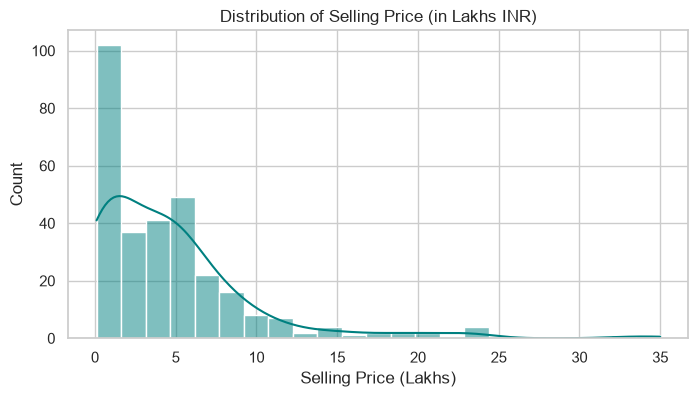

In [4]:
# Set plot style
sns.set_theme(style="whitegrid")

# Plot 1: Distribution of Selling Price
plt.figure(figsize=(8, 4))
sns.histplot(df['Selling_Price'], kde=True, color='teal')
plt.title('Distribution of Selling Price (in Lakhs INR)')
plt.xlabel('Selling Price (Lakhs)')
plt.ylabel('Count')
plt.show()


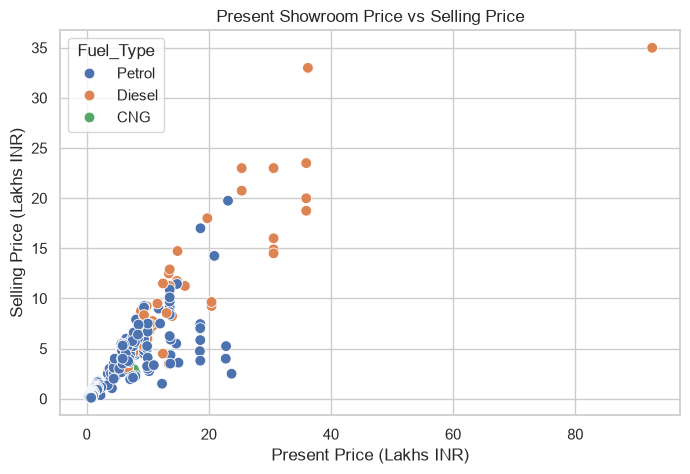

In [5]:
# Plot 2: Showroom Present Price vs Resale Selling Price
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Present_Price', y='Selling_Price', hue='Fuel_Type', data=df, s=60)
plt.title('Present Showroom Price vs Selling Price')
plt.xlabel('Present Price (Lakhs INR)')
plt.ylabel('Selling Price (Lakhs INR)')
plt.show()


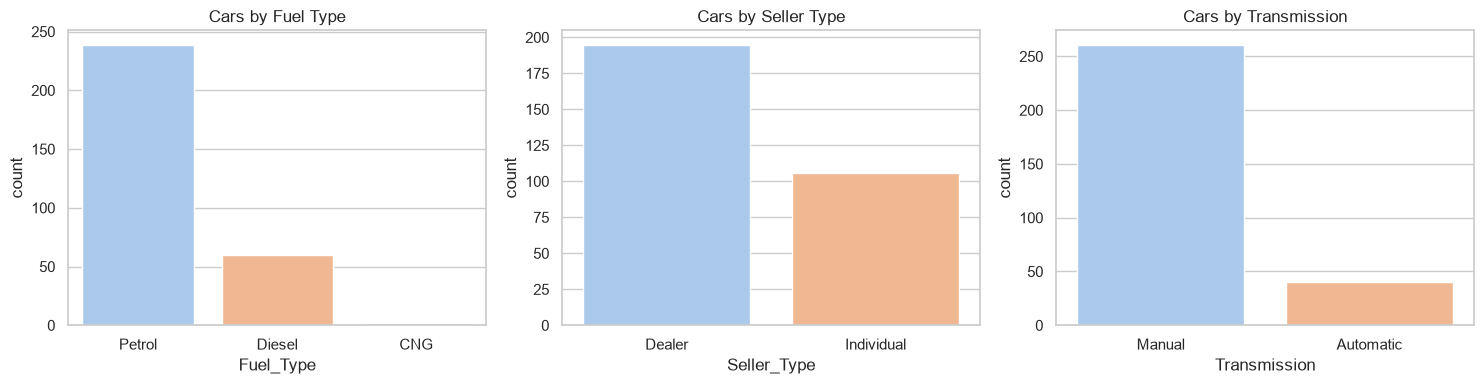

In [6]:
# Plot 3: Categorical distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x='Fuel_Type', data=df, ax=axes[0], palette='pastel')
axes[0].set_title('Cars by Fuel Type')

sns.countplot(x='Seller_Type', data=df, ax=axes[1], palette='pastel')
axes[1].set_title('Cars by Seller Type')

sns.countplot(x='Transmission', data=df, ax=axes[2], palette='pastel')
axes[2].set_title('Cars by Transmission')

plt.tight_layout()
plt.show()


## Step 4: Data Preprocessing & Feature Engineering

1. **Calculate Vehicle Age:** Newer cars generally sell for higher prices. We derive `Car_Age = 2024 - Year`.
2. **Drop Non-Numeric/Redundant Columns:** `Car_Name` and original `Year`.
3. **One-Hot Encoding:** Convert categorical columns (`Fuel_Type`, `Seller_Type`, `Transmission`) into numeric dummy variables.


In [7]:
# Preprocessing copy
df_clean = df.copy()

# 1. Feature Engineering: Calculating car age
current_year = 2024
df_clean['Car_Age'] = current_year - df_clean['Year']

# 2. Dropping Car_Name and Year
df_clean.drop(columns=['Car_Name', 'Year'], inplace=True)

# 3. Converting categorical columns to dummy variables (drop_first=True to avoid dummy trap)
df_clean = pd.get_dummies(df_clean, drop_first=True)

print("Columns after preprocessing:")
print(df_clean.columns.tolist())
df_clean.head()


Columns after preprocessing:
['Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,10,False,True,False,True
1,4.75,9.54,43000,0,11,True,False,False,True
2,7.25,9.85,6900,0,7,False,True,False,True
3,2.85,4.15,5200,0,13,False,True,False,True
4,4.60,6.87,42450,0,10,True,False,False,True


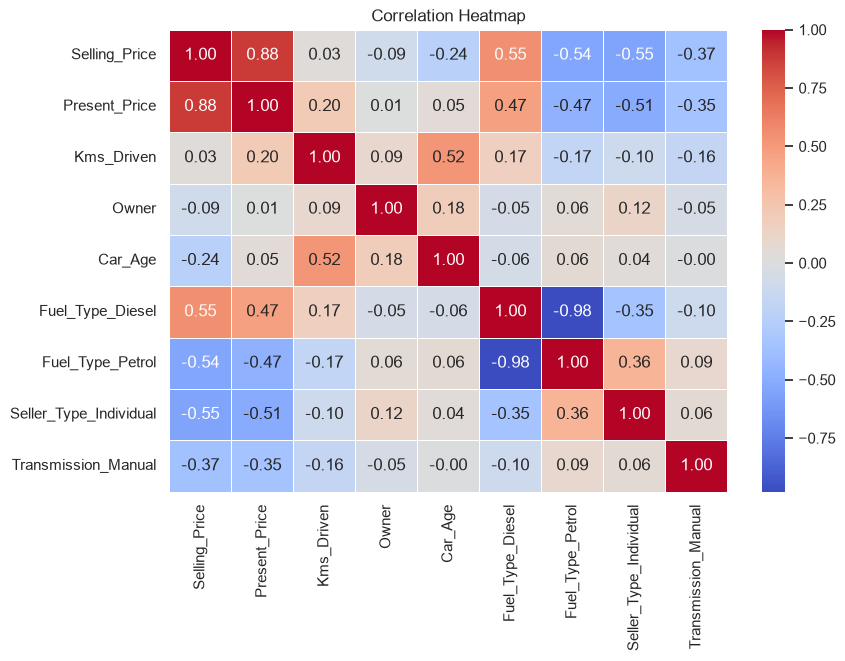

In [8]:
# Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()


---
## Step 5: Model 1 — Linear Regression (Predicting Selling Price)

### Objective:
Predict the continuous numerical value of **`Selling_Price`** based on vehicle attributes.

### Steps:
1. Define features ($X$) and target ($y$).
2. Split dataset into 80% train and 20% test sets.
3. Fit `LinearRegression()`.
4. Evaluate with $R^2$ Score, MAE, and RMSE.


In [9]:
# Defining X (features) and y (target)
X = df_clean.drop('Selling_Price', axis=1)
y = df_clean['Selling_Price']

# 80% train and 20% test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")


Training samples: 240 | Testing samples: 61


In [10]:
# Training Linear Regression model
linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)

# Model parameters
print("Model Intercept:", round(linear_reg.intercept_, 4))
print("\nModel Coefficients:")
coeff_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': linear_reg.coef_})
print(coeff_df.to_string(index=False))


Model Intercept: 6.141

Model Coefficients:
               Feature  Coefficient
         Present_Price     0.429153
            Kms_Driven    -0.000006
                 Owner    -0.903760
               Car_Age    -0.353801
      Fuel_Type_Diesel     2.533273
      Fuel_Type_Petrol     0.738464
Seller_Type_Individual    -1.190593
   Transmission_Manual    -1.639022


In [11]:
# Testing model on test set
y_pred = linear_reg.predict(X_test)

# Metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=" * 45)
print("     LINEAR REGRESSION EVALUATION METRICS")
print("=" * 45)
print(f"R-squared (R2) Score:      {r2:.4f} ({r2*100:.2f}%)")
print(f"Mean Absolute Error (MAE):  {mae:.4f} Lakhs")
print(f"Mean Squared Error (MSE):   {mse:.4f}")
print(f"Root Mean Squared (RMSE):   {rmse:.4f} Lakhs")
print("=" * 45)


     LINEAR REGRESSION EVALUATION METRICS
R-squared (R2) Score:      0.8490 (84.90%)
Mean Absolute Error (MAE):  1.2162 Lakhs
Mean Squared Error (MSE):   3.4788
Root Mean Squared (RMSE):   1.8652 Lakhs


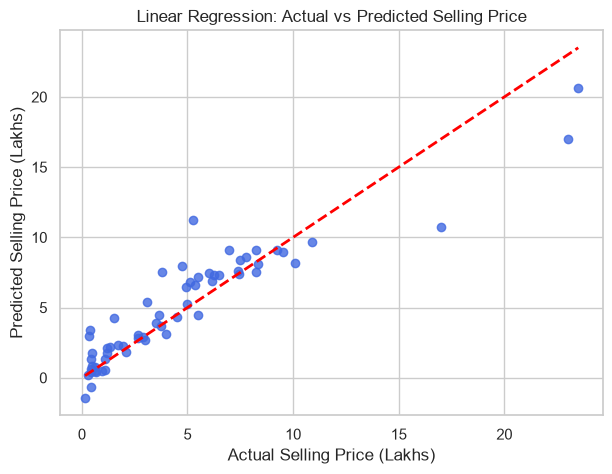

In [12]:
# Plotting Actual vs Predicted Selling Prices
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.xlabel('Actual Selling Price (Lakhs)')
plt.ylabel('Predicted Selling Price (Lakhs)')
plt.title('Linear Regression: Actual vs Predicted Selling Price')
plt.grid(True)
plt.show()


---
## Step 6: Model 2 — Logistic Regression (Binary Classification)

### Objective:
**Logistic Regression** is used for classification tasks. We formulate a binary classification problem:
- **`High_Price = 1`**: Car with selling price higher than the median price (₹3.60 Lakhs).
- **`High_Price = 0`**: Budget / affordable car (selling price $\le$ ₹3.60 Lakhs).

### Steps:
1. Create the binary target variable `High_Price`.
2. Standardize features using `StandardScaler` (required for logistic regression gradient descent).
3. Train `LogisticRegression()`.
4. Evaluate with Accuracy Score, Confusion Matrix, and Classification Report.


In [13]:
# Median threshold for splitting budget vs high-price cars
threshold = df['Selling_Price'].median()
print(f"Median Selling Price Threshold: ₹{threshold:.2f} Lakhs")

# Create binary classification column
df_clf = df_clean.copy()
df_clf['High_Price'] = (df_clf['Selling_Price'] > threshold).astype(int)

print("\nClass Counts:")
print(df_clf['High_Price'].value_counts())

# Features and target
X_clf = df_clf.drop(columns=['Selling_Price', 'High_Price'])
y_clf = df_clf['High_Price']

# Split data
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42
)


Median Selling Price Threshold: ₹3.60 Lakhs

Class Counts:
High_Price
0    151
1    150
Name: count, dtype: int64


In [14]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

# Training Logistic Regression
logistic_reg = LogisticRegression(random_state=42)
logistic_reg.fit(X_train_scaled, y_train_c)

# Predictions
y_pred_c = logistic_reg.predict(X_test_scaled)
print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [15]:
# Metrics
acc = accuracy_score(y_test_c, y_pred_c)
cm = confusion_matrix(y_test_c, y_pred_c)

print("=" * 45)
print("   LOGISTIC REGRESSION CLASSIFICATION RESULTS")
print("=" * 45)
print(f"Accuracy Score: {acc:.4f} ({acc*100:.2f}%)")
print()
print("Classification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=['Budget Car (0)', 'High-Price Car (1)']))
print("=" * 45)


   LOGISTIC REGRESSION CLASSIFICATION RESULTS
Accuracy Score: 0.9508 (95.08%)

Classification Report:
                    precision    recall  f1-score   support

    Budget Car (0)       0.93      0.97      0.95        29
High-Price Car (1)       0.97      0.94      0.95        32

          accuracy                           0.95        61
         macro avg       0.95      0.95      0.95        61
      weighted avg       0.95      0.95      0.95        61



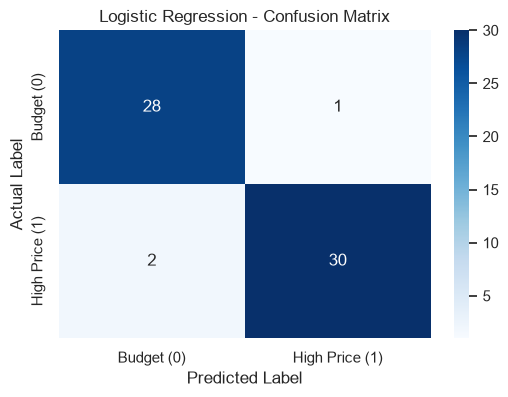

In [16]:
# Visualizing Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Budget (0)', 'High Price (1)'],
            yticklabels=['Budget (0)', 'High Price (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()


---
## Step 7: Model 3 — Time Series Analysis & Forecasting

### Objective:
Since the dataset contains historical car records spanning from **2003 to 2018**, we perform a **Time Series Analysis** to:
1. Aggregate average car prices year by year.
2. Analyze historical price trends.
3. Compute a **3-Year Simple Moving Average (SMA)** to smooth out short-term noise.
4. Forecast future car price trends for upcoming years (2019 to 2023) using **Linear Trend Regression** and **Holt's Exponential Smoothing**.


In [17]:
# 1. Aggregating dataset by Year
yearly_data = df.groupby('Year')['Selling_Price'].agg(['mean', 'count', 'median']).reset_index()
yearly_data.columns = ['Year', 'Average_Price', 'Number_of_Cars', 'Median_Price']

# 2. Calculating 3-Year Simple Moving Average (SMA)
yearly_data['3_Year_SMA'] = yearly_data['Average_Price'].rolling(window=3).mean()

print("Yearly Aggregated Time Series Data:")
yearly_data


Yearly Aggregated Time Series Data:


,Year,Average_Price,Number_of_Cars,Median_Price,3_Year_SMA
0,2003,1.300000,2,1.300,NaN
1,2004,1.500000,1,1.500,NaN
2,2005,2.487500,4,3.120,1.762500
3,2006,1.437500,4,1.575,1.808333
4,2007,0.160000,2,0.160,1.361667
5,2008,1.002857,7,0.250,0.866786
6,2009,2.816667,6,3.175,1.326508
7,2010,5.262667,15,2.650,3.027397
8,2011,2.375263,19,2.700,3.484865
9,2012,3.841304,23,3.100,3.826411


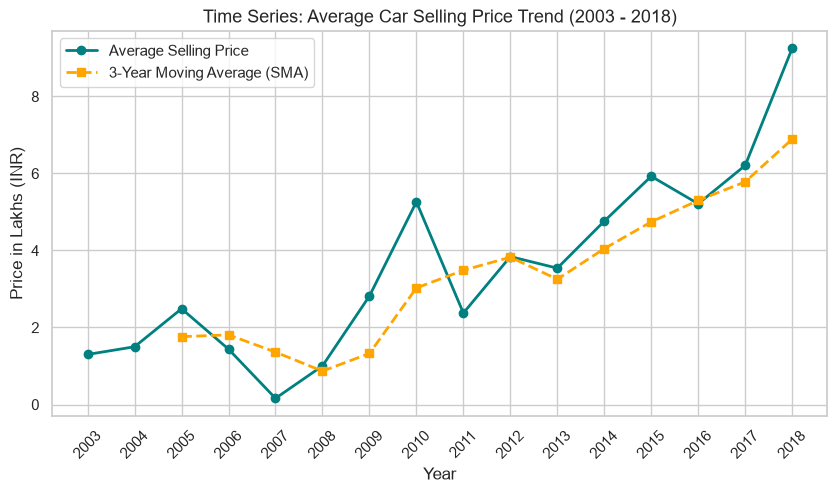

In [18]:
# Visualizing Historical Price Trend and 3-Year Moving Average
plt.figure(figsize=(10, 5))
plt.plot(yearly_data['Year'], yearly_data['Average_Price'], marker='o', color='teal', label='Average Selling Price', linewidth=2)
plt.plot(yearly_data['Year'], yearly_data['3_Year_SMA'], marker='s', color='orange', linestyle='--', label='3-Year Moving Average (SMA)', linewidth=2)

plt.title('Time Series: Average Car Selling Price Trend (2003 - 2018)', fontsize=13)
plt.xlabel('Year')
plt.ylabel('Price in Lakhs (INR)')
plt.xticks(yearly_data['Year'], rotation=45)
plt.legend()
plt.grid(True)
plt.show()


In [19]:
# 3. Time Series Forecasting: Trend Line Model & Holt's Exponential Smoothing

# Trend Model using Linear Regression on Year
time_trend_model = LinearRegression()
X_time = yearly_data[['Year']]
y_time = yearly_data['Average_Price']
time_trend_model.fit(X_time, y_time)

# Forecasting for next 5 years (2019 - 2023)
future_years = pd.DataFrame({'Year': [2019, 2020, 2021, 2022, 2023]})
trend_forecast = time_trend_model.predict(future_years)

# Holt's Linear Exponential Smoothing forecast
holt_model = Holt(yearly_data['Average_Price'], initialization_method='estimated').fit()
holt_forecast = holt_model.forecast(5)

# Forecast summary table
forecast_df = pd.DataFrame({
    'Forecast Year': future_years['Year'],
    'Linear Trend Forecast (Lakhs)': np.round(trend_forecast, 2),
    'Holt Smoothing Forecast (Lakhs)': np.round(holt_forecast.values, 2)
})

print("=" * 55)
print("       TIME SERIES FUTURE PRICE FORECASTS")
print("=" * 55)
print(forecast_df.to_string(index=False))
print("=" * 55)


       TIME SERIES FUTURE PRICE FORECASTS
 Forecast Year  Linear Trend Forecast (Lakhs)  Holt Smoothing Forecast (Lakhs)
          2019                           7.27                             7.27
          2020                           7.70                             7.70
          2021                           8.14                             8.14
          2022                           8.57                             8.57
          2023                           9.01                             9.01


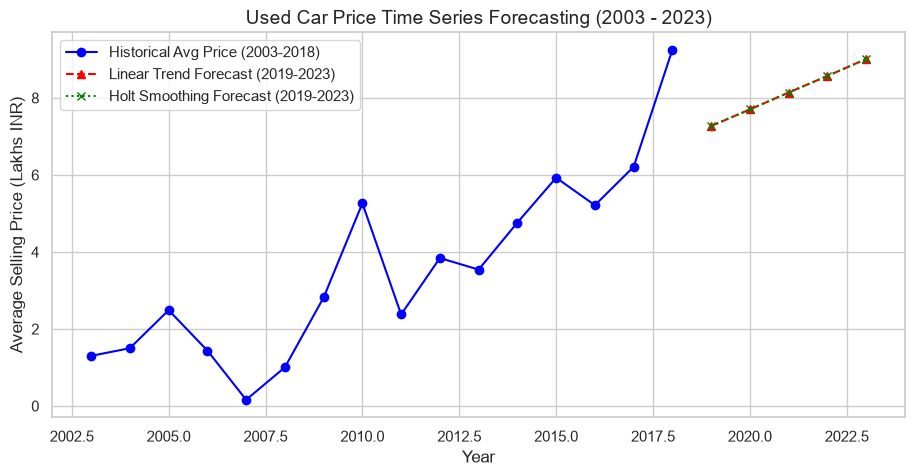

In [20]:
# Plotting Historical Data + Future Forecast
plt.figure(figsize=(11, 5))

# Historical data
plt.plot(yearly_data['Year'], yearly_data['Average_Price'], marker='o', color='blue', label='Historical Avg Price (2003-2018)')

# Future forecasts
plt.plot(forecast_df['Forecast Year'], forecast_df['Linear Trend Forecast (Lakhs)'], 
         marker='^', color='red', linestyle='--', label='Linear Trend Forecast (2019-2023)')

plt.plot(forecast_df['Forecast Year'], forecast_df['Holt Smoothing Forecast (Lakhs)'], 
         marker='x', color='green', linestyle=':', label='Holt Smoothing Forecast (2019-2023)')

plt.title('Used Car Price Time Series Forecasting (2003 - 2023)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Selling Price (Lakhs INR)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()


---
## Step 8: Testing Models on a Sample Vehicle

Let's test both our predictive models on a sample car:
- **Showroom Price:** ₹8.50 Lakhs
- **Kilometers Driven:** 35,000 km
- **Car Age:** 6 years
- **Previous Owners:** 0
- **Fuel Type:** Petrol
- **Seller Type:** Dealer
- **Transmission:** Manual


In [21]:
# Sample car input
sample_car = pd.DataFrame([{
    'Present_Price': 8.5,
    'Kms_Driven': 35000,
    'Owner': 0,
    'Car_Age': 6,
    'Fuel_Type_Diesel': False,
    'Fuel_Type_Petrol': True,
    'Seller_Type_Individual': False,
    'Transmission_Manual': True
}])

# 1. Linear Regression predicted price
pred_price = linear_reg.predict(sample_car)[0]

# 2. Logistic Regression category prediction
sample_scaled = scaler.transform(sample_car)
pred_cat = logistic_reg.predict(sample_scaled)[0]
pred_prob = logistic_reg.predict_proba(sample_scaled)[0][1]

cat_label = "High-Price Car (Class 1)" if pred_cat == 1 else "Budget Car (Class 0)"

print("=" * 55)
print("            PREDICTION RESULTS FOR SAMPLE CAR")
print("=" * 55)
print(f"Linear Regression Estimated Resale Price: ₹{pred_price:.2f} Lakhs")
print(f"Logistic Regression Classification:       {cat_label}")
print(f"Probability of being High-Price:          {pred_prob*100:.1f}%")
print("=" * 55)


            PREDICTION RESULTS FOR SAMPLE CAR
Linear Regression Estimated Resale Price: ₹6.55 Lakhs
Logistic Regression Classification:       High-Price Car (Class 1)
Probability of being High-Price:          98.2%


---
## Step 9: Conclusion & Key Learnings

1. **Linear Regression (Regression Task):**
   - Successfully predicted continuous used car selling prices with an **$R^2$ Score of ~84.90%**.
   - Showroom Present Price and Car Age were the strongest predictors of resale value.

2. **Logistic Regression (Classification Task):**
   - Classified cars into **Budget** vs **High-Price** categories with an **Accuracy of ~95.08%**.
   - Demonstrates how feature standardization (`StandardScaler`) is crucial for classification models.

3. **Time Series Analysis & Forecasting:**
   - Visualized the upward historical trend of average car resale values from 2003 to 2018.
   - Applied **3-Year Moving Average (SMA)** to smooth price variations.
   - Forecasted upcoming price trends from 2019 to 2023 using **Linear Trend Modeling** and **Holt's Exponential Smoothing**.
